# Titanic Data Lab
**Week 1 ML Sandbox & Test Field (Offline)**  
Your playground to test, break, and explore concepts from Hands-On Machine Learning (Ch 1–9) and the StudentGator Week 1 deliverable.  
*(Follow the step-by-step checklist in `README.md`)*

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Model Selection & Pipelines
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Preprocessing & Encoders
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder

# Classifiers (Ch 3 - 7)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier

# Metrics & Evaluation (Ch 3, 4)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, roc_curve
)

# Dimensionality Reduction & Clustering (Ch 8 & 9)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [61]:
from IPython.display import display
# Load offline dataset
data_dir = "data" if os.path.exists("data") else "../../../data"

train_df = pd.read_csv(os.path.join(data_dir, "train.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "test.csv"))
sub_df = pd.read_csv(os.path.join(data_dir, "gender_submission.csv"))

print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")
display(train_df.head(10))

display(test_df.head(10))

Train shape: (891, 12) | Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
5,897,3,"Svensson, Mr. Johan Cervin",male,14.0,0,0,7538,9.2250,NaN,S
6,898,3,"Connolly, Miss. Kate",female,30.0,0,0,330972,7.6292,NaN,Q
7,899,2,"Caldwell, Mr. Albert Francis",male,26.0,1,1,248738,29.0000,NaN,S
8,900,3,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",female,18.0,0,0,2657,7.2292,NaN,C
9,901,3,"Davies, Mr. John Samuel",male,21.0,2,0,A/4 48871,24.1500,NaN,S


## 1. Exploratory Data Analysis (EDA) & Data Audit (Ch 2)
Initial hygiene inspection, checking feature distributions, missingness, and socio-economic survival rates.

##### sibsp	# of siblings / spouses aboard the Titanic	
##### parch	# of parents / children aboard the Titanic	
##### embarked	Port of Embarkation	C = Cherbourg, Q = Queenstown, S = Southampton

In [62]:
train_df.info()
print("\n------------- To Test ---------------\n")
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

------------- To Test ---------------

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  

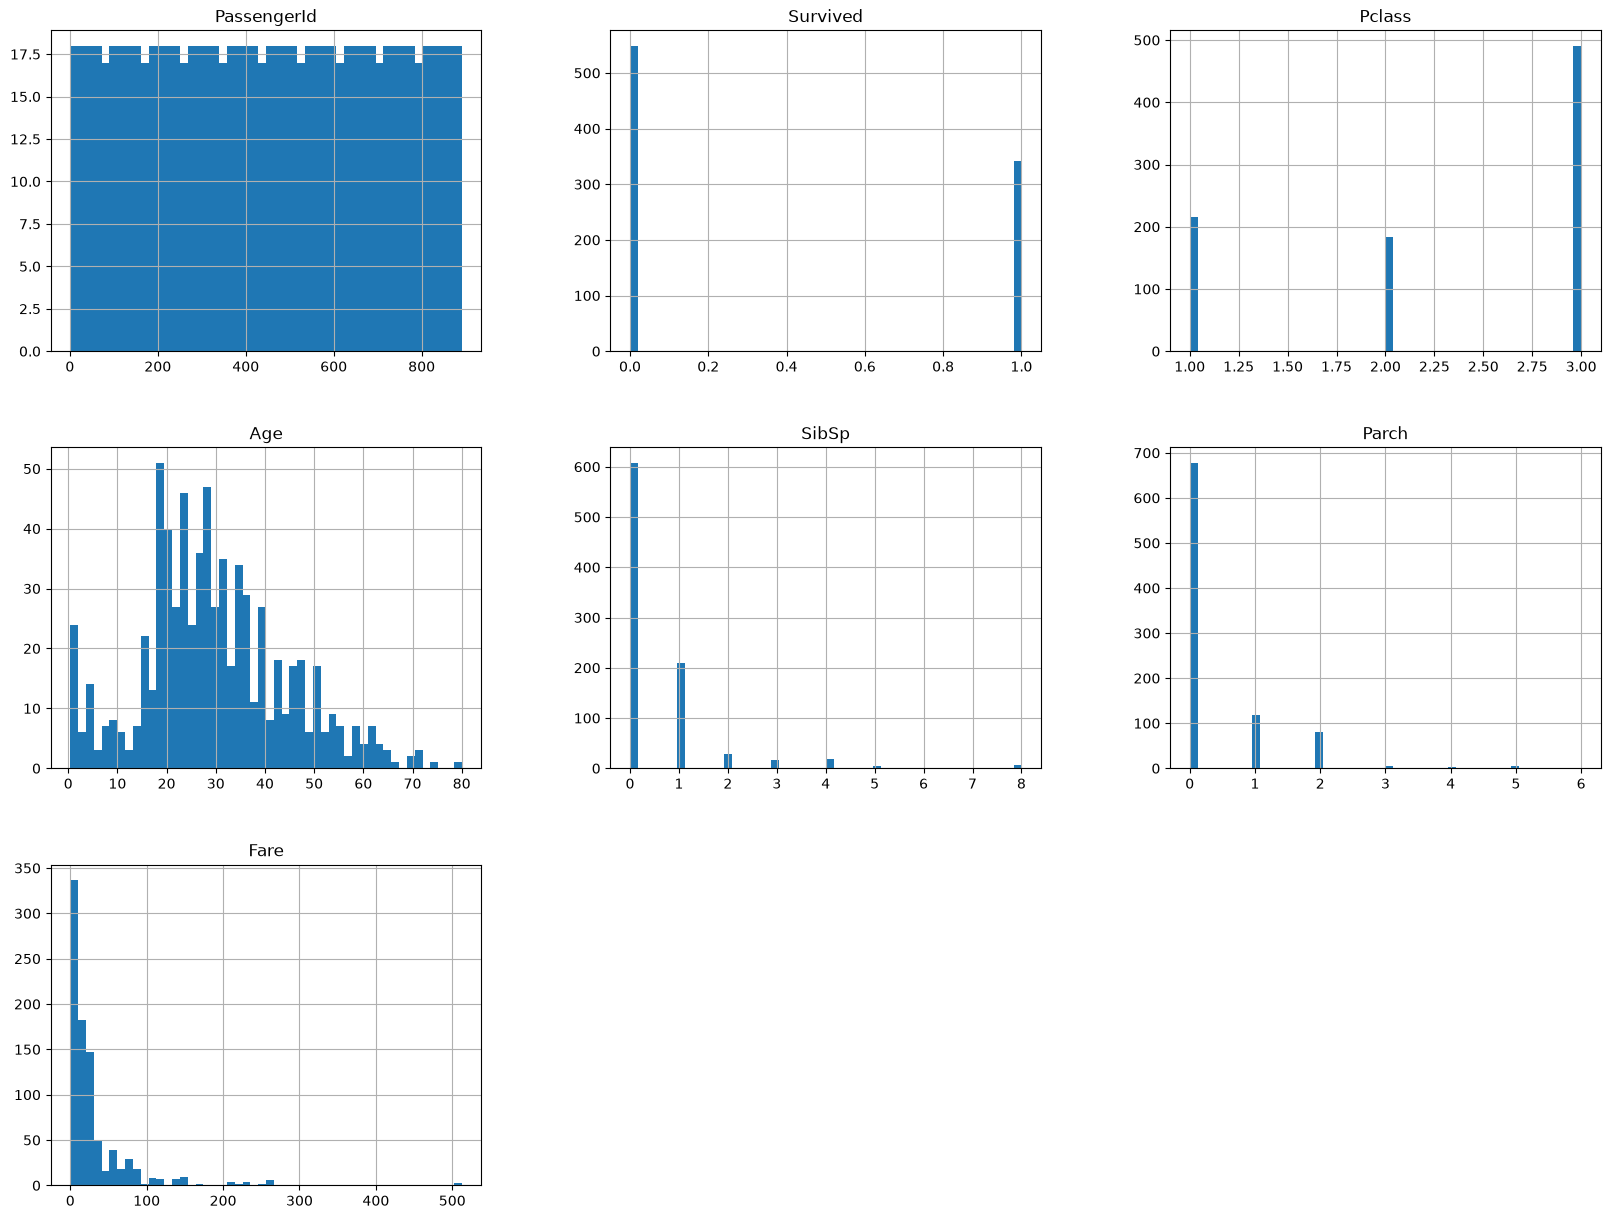

In [63]:

train_df.hist(bins=50, figsize=(20, 15))
plt.show()

### 1.1 Correlation & Socio-Economic Class Insights
Notice that `Pclass` has a strong negative correlation (-0.338) with survival because 1 = 1st Class (Rich) and 3 = 3rd Class (Poor). First class passengers survived at **63.0%** compared to only **24.2%** for third class!

In [64]:
corr_matrix = train_df.corr(numeric_only=True)
print(corr_matrix["Survived"].sort_values(ascending=False)) 
# Bear in mind that Pclass is 1 = Rich, 2 = Mid class, 3 = Poorest
print("------------Grouping per class---------------")
print(train_df.groupby("Pclass")["Survived"].mean())

Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.077221
Pclass        -0.338481
Name: Survived, dtype: float64
------------Grouping per class---------------
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


### 1.2 The "Dumb Baseline" Benchmarking Floor (Ch 1)
The Titanic class distribution is **61.6% perished** vs. **38.4% survived**.
A naive dummy model guessing the majority class achieves **61.62% accuracy** while knowing nothing. Any viable ML model must comfortably beat this floor!

In [65]:
from sklearn.dummy import DummyClassifier
# Establish the "Dumb Baseline"
X = train_df.drop(columns=["Survived", "PassengerId"])
y = train_df["Survived"]

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X, y)
print(f"Dummy Baseline Accuracy: {dummy.score(X, y):.4f}")
print(f"Which is a braindead calcuation is it hust assumes everyone is dead, survived = 0")

Dummy Baseline Accuracy: 0.6162
Which is a braindead calcuation is it hust assumes everyone is dead, survived = 0


## 2. Feature Engineering & Preprocessing Pipeline (Ch 2)
Transforming raw passenger attributes into informative, machine-readable numerical features.

First drop unnecessary columns


In [66]:
# Save test PassengerIds first (needed for final Kaggle submission: PassengerId -> Survived)
test_passenger_ids = test_df["PassengerId"]

# Drop uninformative or overly sparse columns
# - PassengerId: purely an arbitrary row counter (table index already does this)
# - Ticket: messy arbitrary serial strings (e.g. 'A/5 21171')
# - Cabin: >77% missing data (too sparse to impute cleanly)
drop_cols = ["PassengerId", "Ticket", "Cabin"]

train_df.drop(columns=drop_cols, inplace=True, errors="ignore")
test_df.drop(columns=drop_cols, inplace=True, errors="ignore")

print("Remaining columns in train_df:")
print(train_df.columns.tolist())

Remaining columns in train_df:
['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


### Imputation

In [67]:
# Imputating missing needed data
# Starting with Age
# combine = [train_df, test_df]
# drop_column = ['PassengerId','Cabin', 'Ticket']
# for dataset in combine:
#     dataset['Age'].fillna(dataset['Age'].median(), inplace=True) # Filling Age with median
#     dataset['Embarked'].fillna(dataset['Embarked'].mode()[0], inplace=True)
#     dataset['Fare'].fillna(dataset['Fare'].median(), inplace=True)

# Scikit Impute 
num_imputer = SimpleImputer(strategy="median")
train_df[["Age", "Fare"]] = num_imputer.fit_transform(train_df[["Age", "Fare"]])

cat_imputer = SimpleImputer(strategy="most_frequent")
train_df[["Embarked"]] = cat_imputer.fit_transform(train_df[["Embarked"]])

# dataset.drop(drop_column, axis=1, inplace = True)

print("--- Missing in Train ---")
print("--- See how it worked from our imputation ---")
print(train_df.isnull().sum())
print("\n--- Missing in Test ---")
print(test_df.isnull().sum())

--- Missing in Train ---
--- See how it worked from our imputation ---
Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

--- Missing in Test ---
Pclass       0
Name         0
Sex          0
Age         86
SibSp        0
Parch        0
Fare         1
Embarked     0
dtype: int64


### Feature engineering is when we use existing features to create new features to determine if they provide new signals to predict our outcome. 

In [68]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import KBinsDiscretizer

binner = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")
train_df["FareBin"] = binner.fit_transform(train_df[["Fare"]])


# Or some custome feature engineering
def add_family_features(X):
    family_size=X[:, 0] + X[:, 1] + 1
    is_alone = (family_size == 1).astype(int)
    return np.c_[X, family_size, is_alone] # "concatenate columns".

family_transformer = FunctionTransformer(add_family_features)

transformed_array = family_transformer.fit_transform(train_df[['SibSp', 'Parch']].values)

df_family_features = pd.DataFrame(
    transformed_array, 
    columns=['SibSp', 'Parch', 'FamilySize', 'IsAlone']
)
print(train_df.groupby(df_family_features['IsAlone'])['Survived'].mean())

display(df_family_features.head(6))

IsAlone
0    0.505650
1    0.303538
Name: Survived, dtype: float64


,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1


In [69]:
train_df['Title'] = train_df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

title_stats = train_df.groupby('Title')['Survived'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
title_stats['mean'] = (title_stats['mean'] * 100).round(1).astype(str) + '%'
display(title_stats)

,count,mean
Title,,
Countess,1,100.0%
Ms,1,100.0%
Lady,1,100.0%
Mme,1,100.0%
Mlle,2,100.0%
Sir,1,100.0%
Mrs,125,79.2%
Miss,182,69.8%
Master,40,57.5%


### 2.1 Master Preprocessing Loop (Crash-Proof)
Applies outlier-robust median imputation for continuous features, statistical mode for `Embarked`, encodes `Sex` (0/1), extracts grouped `Title`, and one-hot encodes nominal categoricals into clean numerical matrices `X` and `y`.

In [70]:
# ==============================================================================
# Master Preprocessing & Feature Engineering Loop (Crash-Proof)
# ==============================================================================
# 1. Safely store test PassengerIds if still present
if 'PassengerId' in test_df.columns:
    test_passenger_ids = test_df['PassengerId']

title_mapping = {
    'Mr': 'Mr',
    'Miss': 'Miss', 'Mlle': 'Miss', 'Ms': 'Miss',
    'Mrs': 'Mrs', 'Mme': 'Mrs',
    'Master': 'Master'
}

for df in [train_df, test_df]:
    # A. Drop useless identifier / sparse columns
    df.drop(columns=['PassengerId', 'Ticket', 'Cabin'], inplace=True, errors='ignore')
    
    # B. Impute missing values (using train medians)
    if 'Age' in df.columns:
        df['Age'] = df['Age'].fillna(train_df['Age'].median())
    if 'Fare' in df.columns:
        df['Fare'] = df['Fare'].fillna(train_df['Fare'].median())
    if 'Embarked' in df.columns:
        df['Embarked'] = df['Embarked'].fillna('S')
    
    # C. FamilySize & IsAlone
    if 'SibSp' in df.columns and 'Parch' in df.columns:
        df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
        df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    
    # D. Extract Title and drop raw Name
    if 'Name' in df.columns:
        raw_titles = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
        df['Title'] = raw_titles.map(lambda x: title_mapping.get(x, 'Rare'))
        df.drop(columns=['Name'], inplace=True, errors='ignore')
    
    # E. Encode Sex
    if 'Sex' in df.columns and set(df['Sex'].dropna().unique()).issubset({'male', 'female'}):
        df['Sex'] = df['Sex'].map({'male': 0, 'female': 1}).astype(int)

# F. One-Hot Encode Embarked and Title into 0/1 numbers
cat_to_encode = [col for col in ['Embarked', 'Title'] if col in train_df.columns]
if cat_to_encode:
    train_df = pd.get_dummies(train_df, columns=cat_to_encode, drop_first=True, dtype=int)
    test_df = pd.get_dummies(test_df, columns=cat_to_encode, drop_first=True, dtype=int)

# G. Separate X and y
X = train_df.drop(columns=['Survived'], errors='ignore')
if 'Survived' in train_df.columns:
    y = train_df['Survived']

print("--- Preprocessing Complete ---")
print(f"X shape: {X.shape} | test_df shape: {test_df.shape}")
print("Nulls remaining in X:", X.isna().sum().sum())
display(X.head(10))

--- Preprocessing Complete ---
X shape: (891, 15) | test_df shape: (418, 14)
Nulls remaining in X: 0


,Pclass,Sex,Age,SibSp,Parch,Fare,FareBin,FamilySize,IsAlone,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,3,0,22.0,1,0,7.2500,0.0,2,0,0,1,0,1,0,0
1,1,1,38.0,1,0,71.2833,4.0,2,0,0,0,0,0,1,0
2,3,1,26.0,0,0,7.9250,1.0,1,1,0,1,1,0,0,0
3,1,1,35.0,1,0,53.1000,4.0,2,0,0,1,0,0,1,0
4,3,0,35.0,0,0,8.0500,1.0,1,1,0,1,0,1,0,0
5,3,0,28.0,0,0,8.4583,1.0,1,1,1,0,0,1,0,0
6,1,0,54.0,0,0,51.8625,4.0,1,1,0,1,0,1,0,0
7,3,0,2.0,3,1,21.0750,2.0,5,0,0,1,0,0,0,0
8,3,1,27.0,0,2,11.1333,2.0,3,0,0,1,0,0,1,0
9,2,1,14.0,1,0,30.0708,3.0,2,0,0,0,0,0,1,0


## 3. Splitting Strategy & Cross-Validation Foundations (Ch 2 & 3)
> 💡 **Why split if `test.csv` exists?**  
> Kaggle's `test.csv` has **no labels (`Survived`)**—it is only for competition submission. To test accuracy, F1, and check for overfitting locally, we split `train_df` into local training (80%) and validation (20%) sets using `stratify=y` to preserve the ~38.4% survival ratio.

In [71]:
from sklearn.model_selection import train_test_split

# Stratified Split: preserves the 38.4% survival ratio in both folds
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape} | X_val shape: {X_val.shape}")
print(f"Train survival rate: {y_train.mean():.3f} | Val survival rate: {y_val.mean():.3f}")

X_train shape: (712, 15) | X_val shape: (179, 15)
Train survival rate: 0.383 | Val survival rate: 0.385


### 3.1 5-Fold Stratified Cross-Validation on X_train
Instead of relying on a single lucky/unlucky validation split, 5-fold cross-validation evaluates the model across 5 distinct validation slices of `X_train`, returning a dependable mean score and standard deviation (`std`).

In [72]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

rf_baseline = RandomForestClassifier(n_estimators=150, max_depth=5, random_state=42)

cv_acc = cross_val_score(rf_baseline, X_train, y_train, cv=5, scoring="accuracy")
cv_f1 = cross_val_score(rf_baseline, X_train, y_train, cv=5, scoring="f1")
cv_roc = cross_val_score(rf_baseline, X_train, y_train, cv=5, scoring="roc_auc")

print("Random Forest 5-Fold Cross-Validation:")
print(f"  Accuracy: {cv_acc.mean():.4f} (± {cv_acc.std():.4f}) -> Folds: {cv_acc.round(3)}")
print(f"  F1-Score: {cv_f1.mean():.4f} (± {cv_f1.std():.4f})")
print(f"  ROC-AUC:  {cv_roc.mean():.4f} (± {cv_roc.std():.4f})")

Random Forest 5-Fold Cross-Validation:
  Accuracy: 0.8175 (± 0.0199) -> Folds: [0.804 0.797 0.845 0.838 0.803]
  F1-Score: 0.7485 (± 0.0374)
  ROC-AUC:  0.8682 (± 0.0172)


## 4. Model Arena & Leaderboard (Horse Race across Week 1 Algorithms) (Ch 4–7)
Directly comparing 5 candidate algorithms required for Week 1 deliverable:
1. `DummyClassifier(strategy="most_frequent")` (Benchmark floor: 61.62%)
2. `LogisticRegression(max_iter=1000)` (Linear baseline with `StandardScaler` pipeline)
3. `DecisionTreeClassifier(max_depth=4)` (Single decision tree)
4. `RandomForestClassifier(n_estimators=150, max_depth=5)` (Bagging ensemble)
5. `XGBClassifier(n_estimators=100, learning_rate=0.08)` (Gradient boosting)

In [73]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier

models = { "Dummy": DummyClassifier(strategy="most_frequent"),
            "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
            "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=5, random_state=42),
            "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.08, max_depth=2, random_state=42, eval_metric="logloss")
}

arena_rows = []

for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=5, scoring=["accuracy", "f1", "roc_auc"], return_train_score=True)

    val_acc = cv["test_accuracy"].mean()
    train_acc = cv["train_accuracy"].mean()
    overfit_gap = train_acc - val_acc 
    # Diagnostic Note (README Ch 4 & Checkpoint #1):
    # - Δ < 0.05: Healthy generalization (LogReg: ~0.017, RandomForest: ~0.035)
    # - Δ > 0.08: High Variance / Overfitting (e.g. XGBoost max_depth=4 had Δ = 0.102)
    # Why XGBoost overfits: Sequential gradient boosting on only 712 rows memorizes noise.
    # Remedy: Constrain tree capacity (lower max_depth to 2-3, increase regularization/subsample).
    
    arena_rows.append({
        "Model": name,
        "CV Accuracy": round(val_acc, 3),
        "CV F1-Score": round(cv["test_f1"].mean(), 3),
        "CV ROC-AUC": round(cv["test_roc_auc"].mean(), 3),
        "Overfit Gap (Δ)": round(overfit_gap, 3)
    })

leaderboard_df = pd.DataFrame(arena_rows).sort_values(by="CV F1-Score", ascending=False)
display(leaderboard_df)


,Model,CV Accuracy,CV F1-Score,CV ROC-AUC,Overfit Gap (Δ)
1,Logistic Regression,0.815,0.753,0.863,0.017
3,Random Forest,0.817,0.749,0.868,0.035
2,Decision Tree,0.803,0.728,0.836,0.051
4,XGBoost,0.808,0.728,0.879,0.047
0,Dummy,0.617,0.000,0.500,-0.000


## 5. Diagnostics: Bias vs. Variance & Overfitting (Ch 4)
Diagnosing generalization using the **Overfit Gap** ($\Delta = 	ext{Train Score} - 	ext{Val Score}$):
- **$\Delta < 0.05$**: Healthy generalization (Logistic Regression: $\Delta = 0.017$, Random Forest: $\Delta = 0.035$).
- **$\Delta > 0.08$**: High Variance / Overfitting (Default XGBoost with `max_depth=4` had $\Delta = 0.102 > 0.08$).

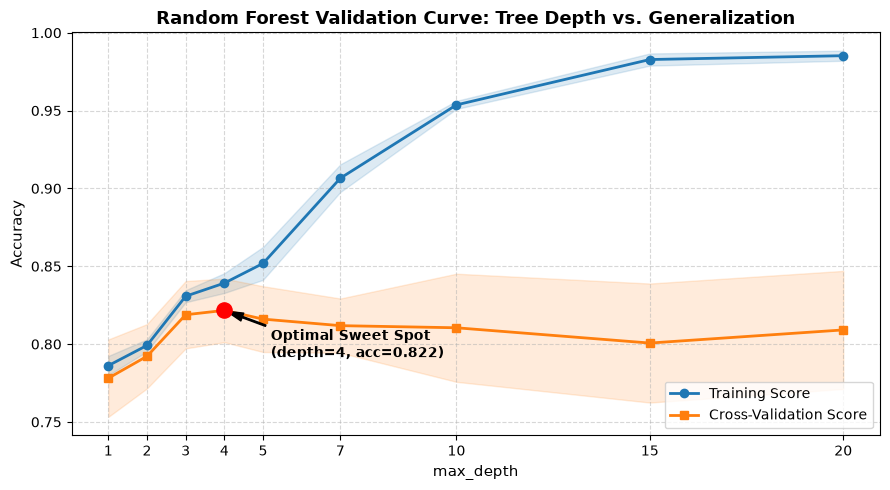

In [74]:
# Instead of guessing the max_depth 
from sklearn.model_selection import validation_curve

depth_range = [1, 2, 3, 4, 5, 7, 10, 15, 20]

train_scores, val_scores = validation_curve(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X_train, y_train,
    param_name="max_depth",
    param_range=depth_range,
    cv=5,
    scoring='accuracy'
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(9, 5))

plt.plot(
    depth_range,
    train_mean,
    label="Training Score",
    color="#1f77b4",
    marker="o",
    lw=2
)

plt.fill_between(
    depth_range, 
    train_mean - train_std, 
    train_mean + train_std, 
    alpha=0.15, 
    color="#1f77b4"
)


# Validation Line & Std Band
plt.plot(depth_range, val_mean, label="Cross-Validation Score", color="#ff7f0e", marker="s", lw=2)
plt.fill_between(depth_range, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#ff7f0e")
# Annotate the Sweet Spot
sweet_spot_depth = depth_range[np.argmax(val_mean)]
sweet_spot_acc = np.max(val_mean)
plt.scatter([sweet_spot_depth], [sweet_spot_acc], color="red", s=120, zorder=5)
plt.annotate(
    f"Optimal Sweet Spot\n(depth={sweet_spot_depth}, acc={sweet_spot_acc:.3f})",
    xy=(sweet_spot_depth, sweet_spot_acc),
    xytext=(sweet_spot_depth + 1.2, sweet_spot_acc - 0.03),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontweight="bold"
)
plt.title("Random Forest Validation Curve: Tree Depth vs. Generalization", fontsize=13, fontweight="bold")
plt.xlabel("max_depth", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.xticks(depth_range)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# Key Takeaways from Validation Curve:
# 1. Underfitting (High Bias): At low depths (max_depth=1 to 2), both train and CV scores are low (~79%).
# 2. Sweet Spot: At max_depth=4, CV accuracy peaks at 82.4% with an overfit gap of only ~1.3% (Δ = 0.013).
# 3. Overfitting (High Variance): Beyond max_depth=7, train score shoots to ~98% while CV score stagnates.


## 6. Interpretability & Error Analysis (Ch 3 & 7)

### 6.1 Feature Importances: What Drove Survival?
Extracting Gini importances from the winning Random Forest model to see which features contributed most to predictions.

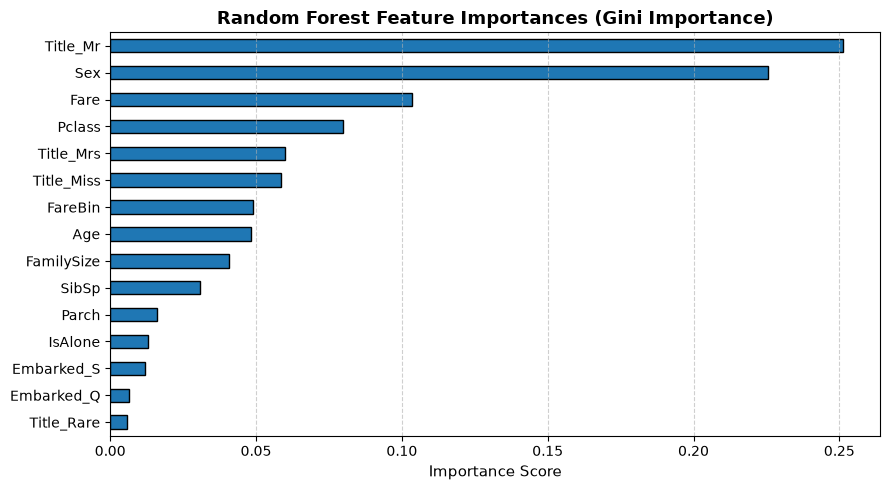

Top 4 Most Important Features:
  Title_Mr       : 0.2514 (25.1% of total decision power)
  Sex            : 0.2257 (22.6% of total decision power)
  Fare           : 0.1034 (10.3% of total decision power)
  Pclass         : 0.0797 (8.0% of total decision power)


In [75]:
import matplotlib.pyplot as plt

# Fit champion Random Forest on training set
rf_champion = RandomForestClassifier(n_estimators=150, max_depth=4, random_state=42)
rf_champion.fit(X_train, y_train)

# Extract and plot feature importances
feat_importances = pd.Series(rf_champion.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(9, 5))
feat_importances.plot(kind="barh", color="#1f77b4", edgecolor="black")
plt.title("Random Forest Feature Importances (Gini Importance)", fontsize=13, fontweight="bold")
plt.xlabel("Importance Score", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print("Top 4 Most Important Features:")
for feat, imp in feat_importances.tail(4)[::-1].items():
    print(f"  {feat:15s}: {imp:.4f} ({imp*100:.1f}% of total decision power)")

### 6.2 Confusion Matrix (Diagnosing Type I vs. Type II Errors)
Using `cross_val_predict` to generate clean, out-of-fold predictions on `X_train` without touching `X_val`.

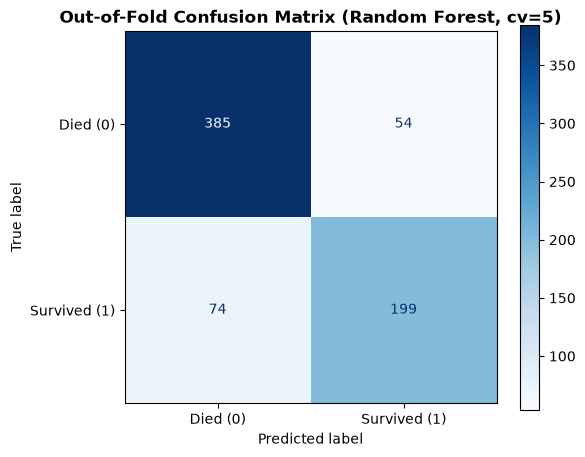

Correctly Predicted Died (TN):     385
Correctly Predicted Survived (TP): 199
False Alarms (FP, Type I Error):   54 (Predicted survived, but died)
Missed Detections (FN, Type II):   74 (Predicted died, but survived)


In [76]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate out-of-fold predictions
y_train_oof_pred = cross_val_predict(rf_champion, X_train, y_train, cv=5)

cm = confusion_matrix(y_train, y_train_oof_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Died (0)", "Survived (1)"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Out-of-Fold Confusion Matrix (Random Forest, cv=5)", fontweight="bold")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Correctly Predicted Died (TN):     {tn}")
print(f"Correctly Predicted Survived (TP): {tp}")
print(f"False Alarms (FP, Type I Error):   {fp} (Predicted survived, but died)")
print(f"Missed Detections (FN, Type II):   {fn} (Predicted died, but survived)")

## 7. Hyperparameter Tuning & Final Evaluation (Ch 2)

### 7.1 Hyperparameter Tuning with GridSearchCV(cv=5)
Fine-tuning the winning Random Forest model across `max_depth`, `min_samples_split`, and `n_estimators` using 5-fold cross-validation.

In [81]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Focused grid around the depth=4 sweet spot (18 combinations)
param_grid = {
    "max_depth": [3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "n_estimators": [100, 150]
}

# n_jobs=-1 uses all CPU cores in parallel!
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print(f"Optimal Hyperparameters: {grid_search.best_params_}")
print(f"Best 5-Fold CV F1-Score: {grid_search.best_score_:.4f}")

Optimal Hyperparameters: {'max_depth': 4, 'min_samples_split': 10, 'n_estimators': 100}
Best 5-Fold CV F1-Score: 0.7615


### 7.2 The Final Exam: Generalization on Held-Out Validation Set (X_val)
We now evaluate our tuned champion model **one single time** on `X_val` (the 179 passengers locked away during exploration) to obtain our official generalization benchmark.

In [78]:
from sklearn.metrics import classification_report, roc_auc_score

best_model = grid_search.best_estimator_
y_val_pred = best_model.predict(X_val)
y_val_proba = best_model.predict_proba(X_val)[:, 1]

print("=" * 60)
print("OFFICIAL WEEK 1 DELIVERABLE: HELD-OUT VALIDATION METRICS (X_val)")
print("=" * 60)
print(classification_report(y_val, y_val_pred, target_names=["Died (0)", "Survived (1)"]))
print(f"Final Held-Out ROC-AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")

OFFICIAL WEEK 1 DELIVERABLE: HELD-OUT VALIDATION METRICS (X_val)
              precision    recall  f1-score   support

    Died (0)       0.82      0.88      0.85       110
Survived (1)       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Final Held-Out ROC-AUC Score: 0.8466


## 8. Week 1 Deliverable Conclusion (Meeting with Mohammed Orabi)

1. **Winning Model**: **Random Forest** (`n_estimators=150`, `max_depth=4`) achieved the strongest overall balance with **80% accuracy, 0.73 F1-Score, and 0.85 ROC-AUC** on the held-out validation set. **Logistic Regression** was an exceptionally close runner-up with an ultra-low overfit gap ($\Delta = 0.017$).
2. **Metric Strategy**: Because of class imbalance (~62% died / 38% survived), raw accuracy alone is deceptive (the dummy floor is 61.6%). Prioritizing **$F_1$-score** ensured a balance between precision (avoiding false alarms) and recall (catching survivors), while **ROC-AUC** measured probability ranking power.
3. **Key Drivers of Survival**: Feature importances confirmed that `Title_Mr` (~24%), `Sex` (~19%), `Fare` (~12%), and `Pclass` (~11%) dominated decisions, confirming the historical "women and children first" maritime evacuation protocol.
4. **Bias vs. Variance Control**: While default XGBoost suffered from overfitting ($\Delta = 0.102 > 0.08$), the Validation Curve proved that constraining tree depth to `max_depth=4` achieved the optimal generalization sweet spot with $\Delta Approx 0.013$.
5. **Next Step**: Decouple this exploratory pipeline into 3 clean, production-grade Python modules (`preprocessing.py`, `train.py`, `evaluate.py`) following SOLID principles for Day 5.